# Tools - Conductance exponent (or resistance exponent) ($d_{\Omega}$)

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Conductance exponent (or resistance exponent)
Consider a graph with conductances $\omega(e)$ or resistances $R(e)=1/\omega(e)$ attached to the edges $e$.

For any pair of nodes $X, Y$ in the graph, let $\omega^{\textit{eq}}(X, Y)$ be the equivalent conductance, or $R^{\textit{eq}}(X, Y) = 1/\omega^{\textit{eq}}(X, Y)$ the equivalent resistance, between the nodes $X$ and $Y$, and let $r(X, Y)$ the Euclidean distance between $X$ and $Y$.

Then, we have the the power law 
- $\omega^{\textit{eq}}\propto r^{-d_\Omega}$

or
- $R^{\textit{eq}}\propto r^{d_\Omega}$

The exponent $d_\Omega$ is the **conductance exponent**  or the **resistance exponent**.



### Computation of conductance exponent

The conductance exponent can be statistically computed by estimating the equivalent conductance (or resistance) between pairs of nodes in a graph randomly selected, and by fitting a line on the log-log plot of $\omega^{eq}$ (the equivalent conductance) as function of $r$ (the distance between the two nodes). Minus the slope of the line is then an estimation of the conductance exponent $d_\Omega$. (Note that the equivalent resistance $R^{eq}$ can be used instead fo the equivalent conductance, then the conductance exponent is (plus) the slope of the fitted line.)

The conductance on the edges can be set proportional to the inverse of their length (or the resistance on the edges proportional to their length).

**Remark.** Computing equivalent conductance implies to calculate the pseudo-inverse of the Laplacian matrix of the graph. For graph with a large amount of nodes, the computation of the pseudo-inverse is heavy, and an approximation (based on the first eigen values and eigen vectors of the Laplacian matrix) can be used.

The dedicated function is `kn.tools.graph_conductance_exponent`.

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import scipy
import time
# import tqdm
# import functools

# import skimage
# import geone as gn

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a percolation cluster in 2D
A binary medium is generatated in a grid, where each cell is independently activated according to a site activation probability. Two activated cells that are adjacent in the grid is in the same connected component (or cluster). A connected component reaching two opposite borders of the grid in a finite grid or a connected component with an infinite number of sites in infinite grid, is said to be percolating.

The corresponding graph has the activated cells as nodes and the edges linking the adjacent nodes (adjacent activated cells in the grid).

The function `kn.misc.random_cluster_in_grid_2d` allows to generate such a graph.

### Percolation threshold
At a critical site activation probability, named **(site) percolation threshold**, noted $p_{critic}$ or $p_c$, the probability of percolation is equal to $0.5$ for finite grid, and the probability of percolation as function of the site activation probability $p$ is a step function going from $0$ to $1$ at the threshold $p=p_c$ for infinite grid.

The theoretical value (for large 2D grid) should be $p_{critic}\approx 0.592746$.

### Conductance exponent

The theoretical value for percolating cluster in (infinite) 2D grid is 
- $d_{\Omega} \approx 0.975$

**Reference (see e.g.)**
- C. D. van Siclen (2021) *Conductivity exponents at the percolation threshold*, axrXiv (https://doi.org/10.48550/arXiv.1609.01229)

[See exponent ration $t/\nu$.]


In [5]:
p_critic = 0.592746 # theoretical value of p_critic for infinite 2D grid

### Generate one percolation cluster

In [6]:
p = p_critic
mx, my = 251, 251
seed = 234

# Get list of graphs corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

In [7]:
# Options for plot of 2D graph
options = {
    'node_size'   : 2,          # node size
    'node_color'  : 'tab:blue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',     # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,      # show node labels ?
    #
    # axes
    'show_ticks'  : True,       # show ticks ?
    'axis_equal'  : True        # aspect ratio equal ?
}

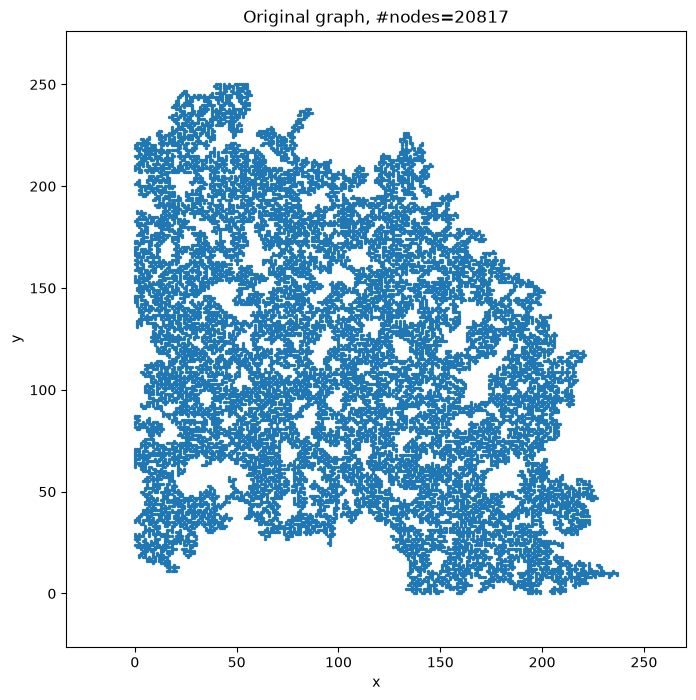

In [8]:
# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')
plt.show()

### Computing equivalent resistance exponent - using the dedicated function

In [9]:
# Set edge weight (w) (conductance)
# ---------------------------------
# Inverse of edge length (here: all length are equal to one)
w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()}

nx.set_edge_attributes(g, w, 'w')

In [10]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = 200 # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
g_lap_eigval, g_lap_eigvec = kn.tools.laplacian_eigs(g, edge_weight='w', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute the first 200 (at max.) eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 152.82 sec


Compute equivalent conductance (10000 pair of nodes) (Laplacian pseudo inverse pre-computed)
Total elapsed time (w_eq for pair of nodes): 0.03 sec
Divide distances into classes, and compute mean on each class (of distance and of equivalent conductance)
Compute conductance exponent (line fitting on log-log plot of equivalent conductance as function of distance)
Fitting on 15 points (over 21)


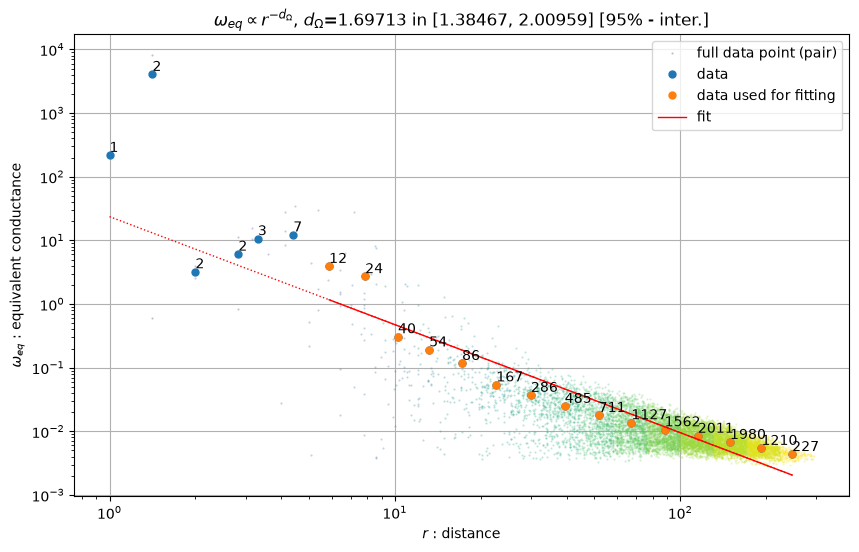

In [11]:
# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

# Compute conductance exponent (- and make plot)
# - parameters for fitting line on log-log plot
npairs = 10000                       # number of pairs of nodes
nclasses = 21                        # number of classes for distances
class_in_log_scale = True            # how the classes are determined
data_points_removed_first_fraction = 0.33 # part of the points removed from the beginning to do the fit
data_points_removed_last_fraction = 0.0   # part of the points removed from the end to do the fit
confidence_level = 0.95              # confidence level for fitting
edge_weight='w'                      # edge weight : conductance

out_dict = kn.tools.graph_conductance_exponent(
        g, 
        npairs,
        nclasses=nclasses,
        class_in_log_scale=class_in_log_scale,
        data_points_removed_first_fraction=data_points_removed_first_fraction,
        data_points_removed_last_fraction=data_points_removed_last_fraction,
        confidence_level=confidence_level,
        edge_weight=edge_weight, 
        eigval=g_lap_eigval, # use pre-computed eigen values 
        eigvec=g_lap_eigvec, # use pre-computed eigen vectors
        return_poly_fit_params=True,
        return_poly_fit_params_cov=True,
        return_starting_index_used_for_fit=True,
        return_dist_mean=True,
        return_weq_mean=True,
        return_nb_points_per_class=True,
        return_class_lim=True,
        return_dist_full=True, #False,
        return_weq_full=True, #False,
        return_class_id_full=True, #False,
        return_pair_nodes_list=True, #False,
        seed=8475,
        verbose=1,
        make_plot=True,
        plot_in_log_scale=True,
        plot_full_data_points=True)

# Show plot
plt.show()

In [13]:
# Show output dictionary (keys and type of values)
for k, v in out_dict.items():
    print(f'key = {k:30s}: value type {type(v)}')

key = dOmega                        : value type <class 'numpy.float64'>
key = dOmega_delta                  : value type <class 'numpy.float64'>
key = confidence_level              : value type <class 'float'>
key = poly_fit_params               : value type <class 'numpy.ndarray'>
key = poly_fit_params_cov           : value type <class 'numpy.ndarray'>
key = index_used_for_fit            : value type <class 'list'>
key = dist_mean                     : value type <class 'numpy.ndarray'>
key = weq_mean                      : value type <class 'numpy.ndarray'>
key = nb_points_per_class           : value type <class 'numpy.ndarray'>
key = class_lim                     : value type <class 'numpy.ndarray'>
key = dist_full                     : value type <class 'numpy.ndarray'>
key = weq_full                      : value type <class 'numpy.ndarray'>
key = class_id_full                 : value type <class 'numpy.ndarray'>
key = pair_nodes_list               : value type <class 'list'>


In [14]:
# Get result from the output dictionary
# - conductance exponent
dOmega = out_dict['dOmega']
dOmega_delta = out_dict['dOmega_delta']
confidence_level = out_dict['confidence_level']

# - mean distances and mean equivalent conductances (array)
dist_mean = out_dict['dist_mean']
weq_mean  = out_dict['weq_mean']
# - number of points (pairs) per class
nb_points_per_class = out_dict['nb_points_per_class']
# - limits of classes
class_lim = out_dict['class_lim']

# - all distances and equivalent conductances, class id, list of pairs of nodes, etc.
dist_full = out_dict['dist_full']
weq_full = out_dict['weq_full']
class_id_full = out_dict['class_id_full']
pair_nodes_list = out_dict['pair_nodes_list']

# - parameters of the fitted polynom (line in log-log scale)
poly_fit_params     = out_dict['poly_fit_params']
poly_fit_params_cov = out_dict['poly_fit_params_cov']
# - starting index of data points sequence used for fitting
index_used_for_fit = out_dict['index_used_for_fit']

In [15]:
# Print conductance exponent
dOmega_lim_min, dOmega_lim_max = dOmega - dOmega_delta, dOmega + dOmega_delta
print(f'Conductance exponent = {dOmega:.5f} in [{dOmega_lim_min:.5f}, {dOmega_lim_max:.5f}] [{100*confidence_level:.2g}% - inter.]')

Conductance exponent = 1.69713 in [1.38467, 2.00959] [95% - inter.]


### Adapt the fit of the line on the log-log plot (if needed)
The function `kn.tools.graph_condutance_exponent_update` allows to update the computation of the conductance exponent (without re-computing equivalent conductance between pairs of nodes) by adapting the classes and the points used for fitting the line on the log-log plot by changing the parameters `nclasses`, `class_in_log_scale`,`data_points_removed_first_fraction`, `data_points_removed_last_fraction` (and `confidence_interval`). 

Note that using the same parameters gives the same results and allows to re-do the plot of the fit. Alternatively, the function `kn.tools.plot_fit_conductance_exponent` can be used to re-do the plot.

Divide distances into classes, and compute mean on each class (of distance and of equivalent conductance)
Compute conductance exponent (line fitting on log-log plot of equivalent conductance as function of distance)
Fitting on 8 points (over 21)


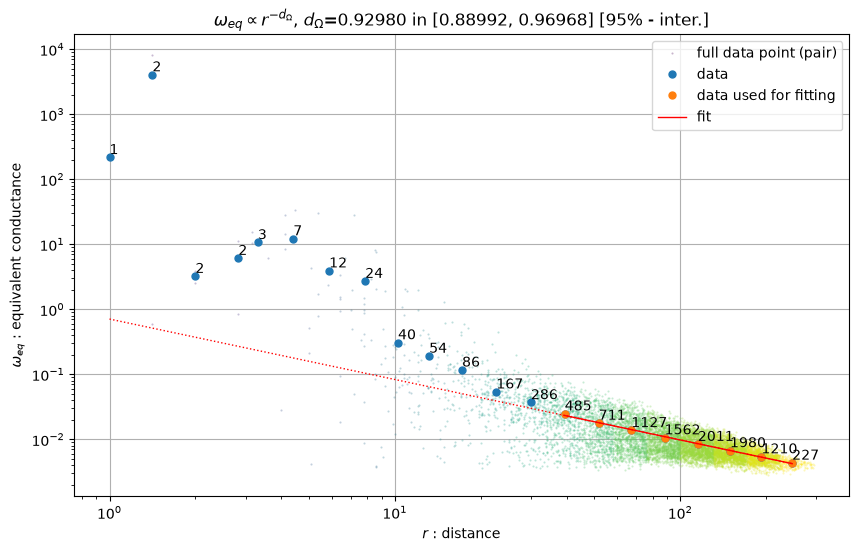

In [16]:
# out_dict_save = out_dict.copy() # save a copy of the results (if wanted)

# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

out_dict = kn.tools.graph_conductance_exponent_update(
        out_dict,
        nclasses=21,
        class_in_log_scale=True,
        data_points_removed_first_fraction=0.66,
        data_points_removed_last_fraction=0.0,
        confidence_level=0.95,
        verbose=1,
        make_plot=True,
        plot_in_log_scale=True,
        plot_full_data_points=True)

# Show plot
plt.show()

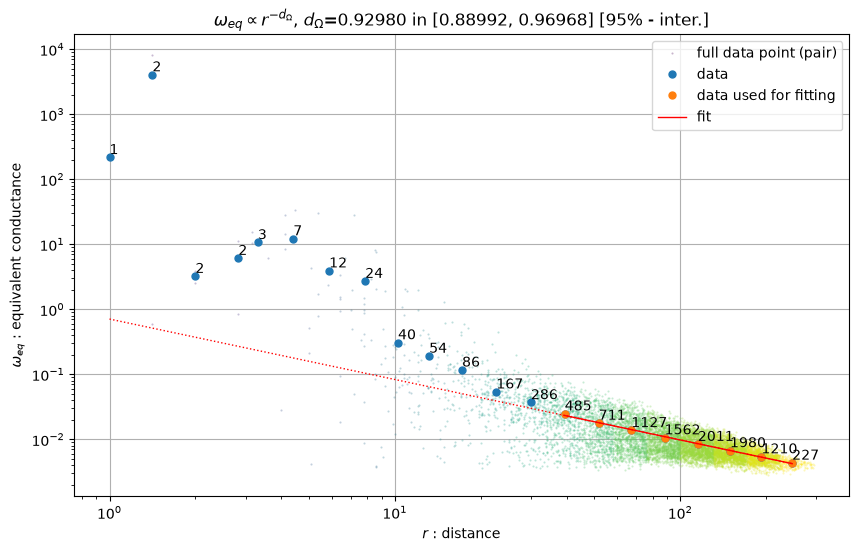

In [18]:
# Re-do the plot (in log-log scale)

# Set figure
plt.figure(figsize=(10, 6))

x_all = out_dict['dist_mean']
y_all = out_dict['weq_mean']
n1, n2 = out_dict['index_used_for_fit']
x = x_all[n1:n2]
y = y_all[n1:n2]
x_full = out_dict['dist_full']
y_full = out_dict['weq_full']
class_id_full = out_dict['class_id_full']
nb_points_per_class = out_dict['nb_points_per_class']
dOmega = out_dict['dOmega']
dOmega_delta = out_dict['dOmega_delta']
confidence_level = out_dict['confidence_level']
poly_fit_params = out_dict['poly_fit_params']

kn.tools.plot_fit_conductance_exponent(
    x_all, y_all, x, y, x_full, y_full, class_id_full, nb_points_per_class, 
    dOmega, dOmega_delta, confidence_level, poly_fit_params, 
    plot_fit=True, plot_in_log_scale=True, plot_full_data_points=True)

# Show plot
plt.show()